# 04 · Variational Autoencoder (VAE)

**Arsitektur:** encoder 784 → 256 → (μ, log σ²) berdimensi 64; decoder 64 → 256 → 784.

**Loss:** L = BCE(x, x̂) + KL( N(μ, σ²) ‖ N(0, I) ), dengan KL = −½ Σ (1 + log σ² − μ² − σ²)

> **Ide utama (loss → visual):**
> Suku **KL** memaksa kode laten setiap gambar berbentuk "awan" kecil di sekitar N(0, I), dan awan-awan itu saling **menempel dan tumpang tindih**. Hasilnya, ruang laten jadi **rapat dan mulus**: tidak ada wilayah kosong, sehingga titik acak dari N(0, I) dan titik hasil interpolasi tetap menghasilkan gambar yang masuk akal.
> Harga yang dibayar: karena z diberi *noise* (reparameterization) dan awan-awan saling tumpang tindih, decoder harus "berkompromi" antar gambar yang mirip. Akibatnya **rekonstruksi VAE biasanya paling buram** di antara keluarga autoencoder.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_train, y_train = splits["train"]
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
HIDDEN_DIM = 256
LATENT_DIM = 64
MAX_EPOCHS = n_epochs(30)
LEARNING_RATE = 1e-3
BETA = 1.0                # bobot KL (beta = 1 -> VAE standar)

## 3. Model

In [4]:
class VAE(nn.Module):
    def __init__(self, hidden=256, latent=64):
        super().__init__()
        self.enc1 = nn.Linear(IMG_SIZE, hidden)
        self.fc_mu = nn.Linear(hidden, latent)        # mu
        self.fc_logvar = nn.Linear(hidden, latent)    # log variance
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden), nn.ReLU(),
            nn.Linear(hidden, IMG_SIZE), nn.Sigmoid())
        self.latent_dim = latent

    def encode(self, x):
        h = F.relu(self.enc1(x.flatten(1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)          # eps ~ N(0, I)
        return mu + eps * std                # z = mu + sigma * eps

    def decode(self, z):
        return self.decoder(z).view(-1, *IMG_SHAPE)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

model = VAE(HIDDEN_DIM, LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Jumlah parameter:", count_params(model))

VAE(
  (enc1): Linear(in_features=784, out_features=256, bias=True)
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Jumlah parameter: 451984


## 4. Loss Function

In [5]:
def loss_fn(model, x):
    x_hat, mu, logvar = model(x)
    B = x.size(0)
    bce = F.binary_cross_entropy(x_hat, x, reduction="sum") / B
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B
    loss = bce + BETA * kl
    mse = F.mse_loss(x_hat, x).item()
    return loss, {"loss": loss.item(), "bce": bce.item(), "kl": kl.item(), "mse": mse}

## 5. Training

In [6]:
history = {"model": "vae", "params": count_params(model), "epoch": [], "iter_loss": [],
           "epoch_time_s": [], "train": [], "val": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    t0 = time.perf_counter()
    sums, n = {}, 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = x.to(device)
        loss, logs = loss_fn(model, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for k, v in logs.items():
            sums[k] = sums.get(k, 0.0) + v
        n += 1
        if it % 10 == 0:
            history["iter_loss"].append(logs["loss"])
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({k: v / n for k, v in sums.items()})

    # validasi
    model.eval()
    vsums, vn = {}, 0
    with torch.no_grad():
        for x, _ in loaders["val"]:
            _, logs = loss_fn(model, x.to(device))
            for k, v in logs.items():
                vsums[k] = vsums.get(k, 0.0) + v
            vn += 1
    history["val"].append({k: v / vn for k, v in vsums.items()})
    history["epoch"].append(epoch)
    tr = history["train"][-1]
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] " + "  ".join(f"{k}: {v:.4f}" for k, v in tr.items())
          + f"  | val loss: {history['val'][-1]['loss']:.4f}  ({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"model": model.state_dict()}, CKPT_DIR / "vae.pt")

Epoch[1/30] loss: 299.8453  bce: 285.1162  kl: 14.7291  mse: 0.0413  | val loss: 274.4171  (1.7s)
Epoch[2/30] loss: 267.7144  bce: 251.1769  kl: 16.5375  mse: 0.0263  | val loss: 263.0874  (1.5s)
Epoch[3/30] loss: 258.5592  bce: 242.9689  kl: 15.5902  mse: 0.0228  | val loss: 255.7584  (1.5s)
Epoch[4/30] loss: 253.1083  bce: 238.0514  kl: 15.0569  mse: 0.0207  | val loss: 252.1014  (1.5s)
Epoch[5/30] loss: 250.1337  bce: 235.1216  kl: 15.0121  mse: 0.0195  | val loss: 250.1185  (1.5s)
Epoch[6/30] loss: 248.2457  bce: 233.1539  kl: 15.0918  mse: 0.0187  | val loss: 248.5262  (1.5s)
Epoch[7/30] loss: 246.9422  bce: 231.7586  kl: 15.1836  mse: 0.0181  | val loss: 247.8088  (1.5s)
Epoch[8/30] loss: 246.0017  bce: 230.7100  kl: 15.2917  mse: 0.0176  | val loss: 246.4756  (1.5s)
Epoch[9/30] loss: 245.2756  bce: 229.8750  kl: 15.4006  mse: 0.0173  | val loss: 246.3762  (1.5s)
Epoch[10/30] loss: 244.5880  bce: 229.1239  kl: 15.4642  mse: 0.0170  | val loss: 245.2424  (1.5s)
Epoch[11/30] loss: 

## 6. Plot Loss History

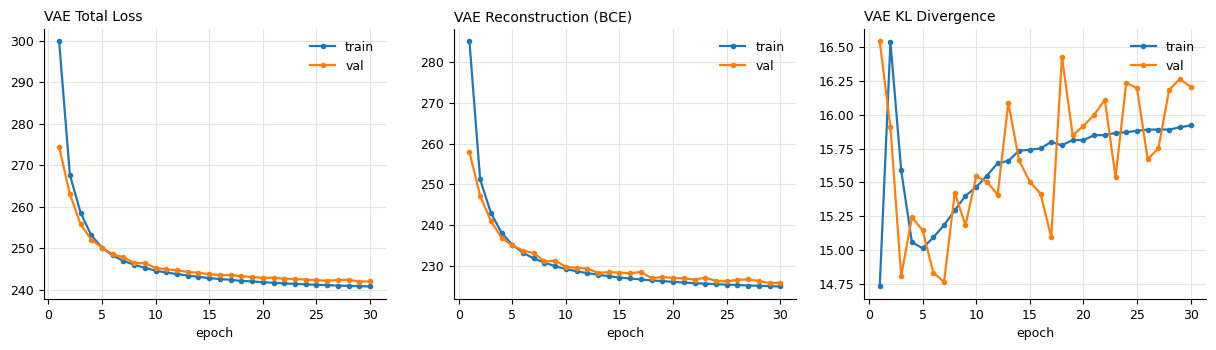

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
ep = history["epoch"]
for ax, key, title in zip(axes, ["loss", "bce", "kl"], ["Total Loss", "Reconstruction (BCE)", "KL Divergence"]):
    ax.plot(ep, [e[key] for e in history["train"]], "-o", ms=3, label="train")
    ax.plot(ep, [e[key] for e in history["val"]], "-o", ms=3, label="val")
    ax.set_title(f"VAE {title}", loc="left"); ax.set_xlabel("epoch"); ax.legend()
plt.show()

## 7. Evaluasi pada Test Set

- **Metrik rekonstruksi:** MSE, PSNR, SSIM pada seluruh Test Set.
- **Latency:** waktu encode + decode untuk 64 citra uji dan untuk 1 citra.
- Untuk VAE, latency diukur saat **menghasilkan gambar baru dari prior** (decode z ~ N(0, I)), karena VAE juga dibandingkan sebagai model generatif.

In [8]:
model.eval()
recon_fn = lambda x: model.decode(model.encode(x)[0])   # VAE dievaluasi memakai mu (deterministik)

metrics = {"model": "vae", "params": count_params(model), "latent_dim": LATENT_DIM,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics.update(reconstruction_metrics(recon_fn, x_test))

gen_fn = lambda n: model.decode(torch.randn(n, LATENT_DIM, device=device))
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = measure_latency(lambda: gen_fn(LATENCY_BATCH))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = measure_latency(lambda: gen_fn(1))
metrics["latency_mode"] = "sampling satu langkah (decode dari prior)"

print(f"Test MSE  : {metrics['mse']:.5f}")
print(f"Test PSNR : {metrics['psnr']:.2f} dB")
print(f"Test SSIM : {metrics['ssim']:.4f}")
print(f"Latency   : {metrics['latency_ms_batch64']:.2f} ms / batch 64 | {metrics['latency_ms_batch1']:.2f} ms / 1 sampel")

Test MSE  : 0.01324
Test PSNR : 19.63 dB
Test SSIM : 0.6465
Latency   : 0.18 ms / batch 64 | 0.16 ms / 1 sampel


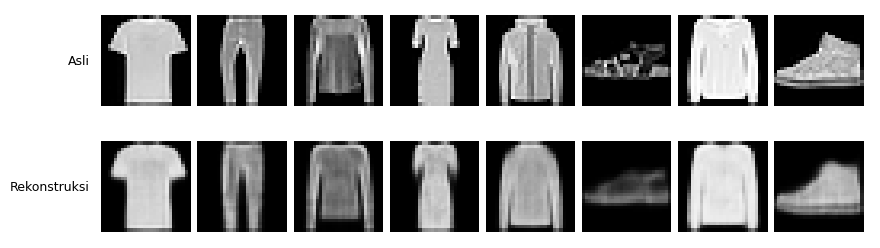

In [9]:
# Visual: baris atas = citra asli, baris bawah = rekonstruksi
x_fix, y_fix = fixed_examples(splits)
with torch.no_grad():
    recon_fix = recon_fn(x_fix.to(device)).cpu()
fig, axes = plt.subplots(2, 1, figsize=(10, 3))
show_imgs(axes[0], x_fix, label="Asli")
show_imgs(axes[1], recon_fix, label="Rekonstruksi")
plt.show()

## 8. Analisis Tambahan untuk Pertanyaan Penelitian

### 8b. Deteksi anomali dengan reconstruction error (Q6 bagian 1)

In [10]:
anomaly = anomaly_auroc(recon_fn, x_test)
print(anomaly)

{'auroc': 0.6983503775510204, 'err_normal_mean': 0.013242747634649277, 'err_defect_mean': 0.01907259225845337, 'err_ratio': 1.4402291774749756}


### 8d. Interpolasi laten (Figur 4 & Q4)
z_A = kode laten citra uji kelas A, z_B = kode laten citra uji kelas B. `bank` = kode laten 5.000 data latih, dipakai untuk mendeteksi *latent voids*.

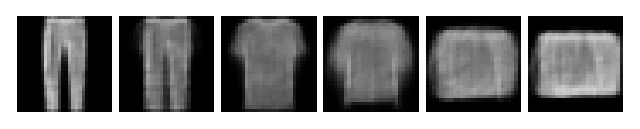

{'model': 'vae', 'alpha': 0.0, 'nn_dist_ratio': 0.9779897928237915, 'classifier_max_conf': 0.9999997615814209, 'pixel_change_from_prev': 0.0}
{'model': 'vae', 'alpha': 0.2, 'nn_dist_ratio': 1.0848677158355713, 'classifier_max_conf': 0.8761898875236511, 'pixel_change_from_prev': 0.0751974955201149}
{'model': 'vae', 'alpha': 0.4, 'nn_dist_ratio': 1.0804951190948486, 'classifier_max_conf': 0.46889084577560425, 'pixel_change_from_prev': 0.0697873905301094}
{'model': 'vae', 'alpha': 0.6, 'nn_dist_ratio': 0.9265369772911072, 'classifier_max_conf': 0.49096646904945374, 'pixel_change_from_prev': 0.08473316580057144}
{'model': 'vae', 'alpha': 0.8, 'nn_dist_ratio': 1.2982312440872192, 'classifier_max_conf': 0.9941006302833557, 'pixel_change_from_prev': 0.10432029515504837}
{'model': 'vae', 'alpha': 1.0, 'nn_dist_ratio': 1.8560360670089722, 'classifier_max_conf': 0.9999475479125977, 'pixel_change_from_prev': 0.07932800054550171}


In [11]:
clf = load_mlp_classifier()
xa, xb = interp_endpoints(splits)
enc = (lambda x: model.encode(x)[0])
with torch.no_grad():
    za, zb = enc(xa.to(device)), enc(xb.to(device))
    bank = apply_batched(enc, x_train[:5000]).to(device)
interp_imgs, interp_rows = interpolation_record("vae", za, zb, model.decode, clf, bank)
fig, ax = plt.subplots(figsize=(8, 1.6)); show_imgs(ax, interp_imgs); plt.show()
for r in interp_rows:
    print(r)

### 8e. Sampling generatif dari prior z ~ N(0, I) + FID + mode coverage (Q1, Figur 2)

FID: 87.85804463282273
Mode coverage: {'class_hist': [0.10379999876022339, 0.08619999885559082, 0.06719999760389328, 0.12720000743865967, 0.08399999886751175, 0.11760000139474869, 0.0729999989271164, 0.1459999978542328, 0.12600000202655792, 0.0689999982714653], 'entropy_norm': 0.9847231507301331, 'modes_covered': 10}


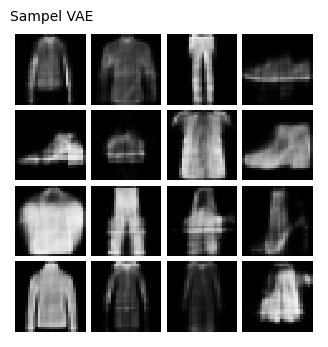

In [12]:
g = torch.Generator(device=device).manual_seed(SEED)
with torch.no_grad():
    samples = torch.cat([model.decode(torch.randn(min(500, FID_NUM_SAMPLES - i), LATENT_DIM, device=device, generator=g)).cpu()
                         for i in range(0, FID_NUM_SAMPLES, 500)])
metrics["fid"] = compute_fid(samples, splits)
metrics["mode_coverage"] = mode_coverage(samples, clf)
print("FID:", metrics["fid"])
print("Mode coverage:", metrics["mode_coverage"])
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel VAE"); plt.show()

## 9. Simpan Hasil untuk Laporan

In [13]:
metrics["stability"] = stability_summary(history)
metrics["anomaly"] = anomaly
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
                      "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM}
metrics["hparams"]["beta"] = BETA
save_results("vae", metrics, artifacts={"recon_fixed": recon_fix, "x_fixed": x_fix, "interp_imgs": interp_imgs, "interp_rows": interp_rows, "samples16": samples[:16]}, history=history)

Hasil 'vae' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
